# Experiment 3: memory × message passing in ST-GNN

This notebook trains the controlled factorial ablation defined in
`STGNN_GRAPH_VALUE_RESEARCH_PLAN.md`, using the **original binary Infilteration labels**.
Run the cells in order in Google Colab with a GPU. All text and generated artifacts use English.

| Cell | Persistent endpoint memory | Inter-node GAT messages |
| --- | --- | --- |
| M0_P0 | No | No |
| M0_P1 | No | Yes |
| M1_P0 | Yes | No |
| M1_P1 | Yes | Yes |

All four cells use the same projected flow attributes, incoming/outgoing endpoint means,
normalization, hidden width, GRU, edge classifier, loss, optimizer, ordered windows,
and training schedule. **M0 is trained with a zero GRU prior at every window and never stores state.**
M1_P1 inherits the existing `ST_GNN_Identity` forward pass unchanged.

The primary comparison matches widths. A second comparison replaces only the two nodewise
linear layers with nodewise MLPs whose parameter counts approximate the corresponding GAT
layers. Both comparisons are reported: the MLP changes the encoder depth, so parameter
matching is a capacity sensitivity analysis. The two GAT cells are shared between comparisons.
Default cost: **30 training runs** (20 primary + 10 parameter sensitivity), each at most 60 epochs.

Protocol: seeds `42, 123, 777, 2024, 99`; Adam `lr=0.005`; weighted BCE `pos_weight=2`;
10 windows per optimizer update/TBPTT segment; validation AP early stopping
(`patience=10`, `min_delta=0.0001`); validation max-F1 thresholds; strict `score > threshold`.
Each split starts with empty memory, with no train-to-validation or validation-to-test warmup.
Test 1 evaluates every completed seed; Test 2 evaluates only champions selected by the
existing validation F1 one-standard-deviation rule and earliest best epoch.

Use the existing 30-second graphs without rebuilding or repartitioning: Wednesday's
chronological 70/15/15 **duration** partitions (assigned by window start) and Thursday Test 2.
Thresholds, architecture settings, and the 1% global ranking budget are fixed before test evaluation.
Test 2 is an **exploratory reuse of an already analyzed day**, not independent confirmation.
Window times and first-hit delays are retrospective, not online detection latency.

Results are saved after every completed seed in a new Drive directory. Completed runs are
verified and reused; interrupted runs restart. Failed runs remain visible and are retried only
when `RETRY_FAILED=True`. A cell with missing or failed seeds receives no champion.
Edge GRU remains an external baseline; ST Uniform remains an attention diagnostic.
Neither enters the four-cell factorial contrasts.

In [ ]:
import importlib.util
import subprocess
import sys
from pathlib import Path

for package in ('torch_geometric', 'pyarrow'):
    if importlib.util.find_spec(package) is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', package], check=True)

from google.colab import drive
drive.mount('/content/drive')

DRIVE_ROOT = Path('/content/drive/MyDrive/nids-mitre')
CLONE_DIR = Path('/content/temporalgnn-nids-factorial-utils')
SOURCE_COMMIT = '2262b53d155f9e8cf5221516f47e4170e6cd0d6e'
if not CLONE_DIR.exists():
    subprocess.run(['git', 'clone', '--no-checkout',
                    'https://github.com/tatipar/temporalgnn-nids.git', str(CLONE_DIR)], check=True)
subprocess.run(['git', '-C', str(CLONE_DIR), 'fetch', '--depth', '1',
                'origin', SOURCE_COMMIT], check=True)
subprocess.run(['git', '-C', str(CLONE_DIR), 'checkout', '--detach', SOURCE_COMMIT], check=True)
actual_commit = subprocess.check_output(
    ['git', '-C', str(CLONE_DIR), 'rev-parse', 'HEAD'], text=True).strip()
assert actual_commit == SOURCE_COMMIT
sys.path.insert(0, str(CLONE_DIR / 'code/python'))
sys.path.insert(0, '/content')
print('Pinned utility/model commit:', actual_commit)

Mounted at /content/drive
Pinned utility/model commit: 2262b53d155f9e8cf5221516f47e4170e6cd0d6e


In [ ]:
import gc
import hashlib
import json
import os
import platform
import shutil
import time
import traceback
from datetime import datetime, timezone

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch_geometric
from IPython.display import display
from sklearn.metrics import average_precision_score
from torch_geometric.loader import DataLoader

from utils.datasets import NF_IDS_Dataset
from utils.models import ST_GNN_Identity, EdgeGRU_Baseline_NoX
from utils.training import train_epoch, evaluate, find_optimal_threshold, set_seed
from utils.experiment import EarlyStopping, NumpyEncoder
from utils.metrics import calculate_metrics_gnn
from utils.evaluation import apply_1sd_rule

NOTEBOOK_VERSION = 'experiment3_factorial_v1'
SEEDS = [42, 123, 777, 2024, 99]
PARAMS = dict(node_dim=16, edge_dim=32, hidden_dim=32,
              dropout=0.2, output_bias_init=-2.9968)
TRAINING = dict(epochs=60, batch_steps=10, learning_rate=0.005,
                pos_weight=2.0, patience=10, min_delta=0.0001)
RUN_PARAMETER_SENSITIVITY = True
RETRY_FAILED = False
INCLUDE_EXTERNAL_BASELINE = True
ALERT_BUDGET_FRACTION = 0.01  # Global top-K ranking diagnostic; no test-label selection.
NUM_WORKERS = 2
WINDOW_SECONDS = 30
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

DAY1_ROOT = DRIVE_ROOT / 'dataset_processed'
DAY2_ROOT = DRIVE_ROOT / 'dataset_processed_thu0103'
ORIGINAL_RESULTS = DRIVE_ROOT / 'results_earlystopping'
SPATIAL_RESULTS = DRIVE_ROOT / 'results_stgnn_spatial_ablation_v1'
OUTPUT = DRIVE_ROOT / 'results_stgnn_memory_message_factorial_v1'
OUTPUT.mkdir(parents=True, exist_ok=True)
(OUTPUT / 'alignment').mkdir(exist_ok=True)

def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, 'rb') as handle:
        for block in iter(lambda: handle.read(8 * 1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

def json_digest(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, cls=NumpyEncoder).encode()).hexdigest()

def write_json(path, value):
    path = Path(path)
    tmp = path.with_name(path.name + '.tmp')
    tmp.write_text(json.dumps(value, indent=2, cls=NumpyEncoder, allow_nan=False))
    os.replace(tmp, path)

def cleanup():
    gc.collect()
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()

print('Device:', DEVICE, '| GPU:', torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else 'none')
print('Output:', OUTPUT)

Device: cpu | GPU: none
Output: /content/drive/MyDrive/nids-mitre/results_stgnn_memory_message_factorial_v1


## 1. Controlled encoders

The no-message encoder ignores `edge_index` after constructing endpoint means. The existing
graph LayerNorm is retained in every cell, including its graph-wide normalization statistics;
therefore P0 means **no learned inter-node propagation**, not statistically independent nodes.
Current-window means include the target flow, as in the original model. This experiment does
not remove that information or change feature availability.

For a given seed, the inherited edge projection, normalizations, GRU, and classifier have
identical initial weights in all cells. Both memory settings also share the encoder's initial
weights. No dormant GAT parameters are counted as trainable capacity in P0 models.
The following cell writes the exact model implementation, which is hashed and archived on Drive.

In [ ]:
%%writefile /content/stgnn_factorial_models.py
import torch
from torch import nn
from utils.models import ST_GNN_Identity


class NodewiseLinear(nn.Module):
    def __init__(self, in_dim, out_dim):
        super().__init__()
        self.linear = nn.Linear(in_dim, out_dim)

    def forward(self, x, edge_index, edge_attr=None):
        return self.linear(x)


class ParameterMatchedNodewise(nn.Module):
    def __init__(self, in_dim, out_dim, target_parameters):
        super().__init__()
        # Two affine layers: width * (in_dim + out_dim + 1) + out_dim parameters.
        estimate = (target_parameters - out_dim) / (in_dim + out_dim + 1)
        candidates = {max(1, int(estimate)), max(1, int(estimate) + 1)}
        self.inner_dim = min(candidates, key=lambda width:
                             (abs(width * (in_dim + out_dim + 1) + out_dim
                                  - target_parameters), width))
        self.net = nn.Sequential(nn.Linear(in_dim, self.inner_dim), nn.ELU(),
                                 nn.Linear(self.inner_dim, out_dim))

    def forward(self, x, edge_index, edge_attr=None):
        return self.net(x)


class FactorialSTGNN(ST_GNN_Identity):
    def __init__(self, node_dim, edge_dim, hidden_dim, dropout=0.2,
                 output_bias_init=None, persistent_memory=True,
                 message_passing=True, nodewise_kind='linear'):
        super().__init__(node_dim, edge_dim, hidden_dim, dropout, output_bias_init)
        self.persistent_memory = persistent_memory
        self.message_passing = message_passing
        if not message_passing:
            targets = [sum(p.numel() for p in layer.parameters())
                       for layer in (self.gnn1, self.gnn2)]
            # Preserve the base-class RNG position for downstream stochastic operations.
            with torch.random.fork_rng(devices=[]):
                if nodewise_kind == 'linear':
                    self.gnn1 = NodewiseLinear(2 * node_dim, hidden_dim)
                    self.gnn2 = NodewiseLinear(hidden_dim, hidden_dim)
                elif nodewise_kind == 'parameter_matched':
                    self.gnn1 = ParameterMatchedNodewise(2 * node_dim, hidden_dim, targets[0])
                    self.gnn2 = ParameterMatchedNodewise(hidden_dim, hidden_dim, targets[1])
                else:
                    raise ValueError(f'Unknown nodewise encoder: {nodewise_kind}')

    def get_memory(self, ids, device):
        if self.persistent_memory:
            return super().get_memory(ids, device)
        return torch.zeros((ids.numel(), self.hidden_dim), device=device,
                           dtype=self.gru.weight_hh.dtype)

    def update_memory(self, ids, h_new):
        if self.persistent_memory:
            super().update_memory(ids, h_new)
        # M0 never carries a state to another window during training or evaluation.

Writing /content/stgnn_factorial_models.py


In [ ]:
import stgnn_factorial_models
importlib.reload(stgnn_factorial_models)
from stgnn_factorial_models import FactorialSTGNN

MODEL_SOURCE = Path('/content/stgnn_factorial_models.py')
MODEL_SHA256 = sha256_file(MODEL_SOURCE)
CELLS = {
    'M0_P0': dict(memory=0, messages=0, nodewise_kind='linear', comparison='matched_width'),
    'M0_P1': dict(memory=0, messages=1, nodewise_kind='linear', comparison='shared_GAT'),
    'M1_P0': dict(memory=1, messages=0, nodewise_kind='linear', comparison='matched_width'),
    'M1_P1': dict(memory=1, messages=1, nodewise_kind='linear', comparison='shared_GAT'),
}
if RUN_PARAMETER_SENSITIVITY:
    CELLS.update({
        'M0_P0_param': dict(memory=0, messages=0, nodewise_kind='parameter_matched',
                            comparison='matched_parameters'),
        'M1_P0_param': dict(memory=1, messages=0, nodewise_kind='parameter_matched',
                            comparison='matched_parameters'),
    })
COHORTS = {'matched_width': ['M0_P0', 'M0_P1', 'M1_P0', 'M1_P1']}
if RUN_PARAMETER_SENSITIVITY:
    COHORTS['matched_parameters'] = ['M0_P0_param', 'M0_P1', 'M1_P0_param', 'M1_P1']

def make_model(cell):
    spec = CELLS[cell]
    return FactorialSTGNN(**PARAMS, persistent_memory=bool(spec['memory']),
                          message_passing=bool(spec['messages']),
                          nodewise_kind=spec['nodewise_kind'])

parameter_rows = []
for cell, spec in CELLS.items():
    set_seed(SEEDS[0])
    model = make_model(cell)
    parameter_rows.append(dict(
        cell=cell, **spec,
        total_parameters=sum(p.numel() for p in model.parameters()),
        trainable_parameters=sum(p.numel() for p in model.parameters() if p.requires_grad),
        encoder_parameters=sum(p.numel() for layer in (model.gnn1, model.gnn2)
                               for p in layer.parameters()),
        nodewise_inner_widths=[getattr(layer, 'inner_dim', None)
                              for layer in (model.gnn1, model.gnn2)],
    ))
    del model
parameter_counts = pd.DataFrame(parameter_rows)
gat_count = int(parameter_counts.loc[parameter_counts.cell == 'M1_P1', 'trainable_parameters'].iloc[0])
parameter_counts['relative_parameter_gap_to_GAT'] = (
    parameter_counts.trainable_parameters / gat_count - 1)
parameter_counts.to_csv(OUTPUT / 'parameter_counts.csv', index=False)
display(parameter_counts)

,cell,memory,messages,nodewise_kind,comparison,total_parameters,trainable_parameters,encoder_parameters,nodewise_inner_widths,relative_parameter_gap_to_GAT
0,M0_P0,0,0,linear,matched_width,12753,12753,2112,"[None, None]",-0.368945
1,M0_P1,0,1,linear,shared_GAT,20209,20209,9568,"[None, None]",0.000000
2,M1_P0,1,0,linear,matched_width,12753,12753,2112,"[None, None]",-0.368945
3,M1_P1,1,1,linear,shared_GAT,20209,20209,9568,"[None, None]",0.000000
4,M0_P0_param,0,0,parameter_matched,matched_parameters,20195,20195,9554,"[97, 49]",-0.000693
5,M1_P0_param,1,0,parameter_matched,matched_parameters,20195,20195,9554,"[97, 49]",-0.000693


## 2. Frozen graph partitions, provenance, and flow alignment

This reads and hashes the existing graph files; it does not create new graphs. The first pass
can take time on Drive. Every flow is identified by `(split, graph filename, edge index)`.
`flow_index` joins each score artifact to the corresponding alignment Parquet file.
The manifest links that index to the exact graph bytes, model source, pinned utilities,
preprocessing notebook hashes, configuration, and software versions.
Source/destination numeric IDs are scoped to their capture day and are never joined across days.

In [ ]:
SPLITS = {
    'train': (DAY1_ROOT, 'train', '2018-02-28'),
    'val': (DAY1_ROOT, 'val', '2018-02-28'),
    'test1': (DAY1_ROOT, 'test', '2018-02-28'),
    'test2': (DAY2_ROOT, 'test2', '2018-03-01'),
}
datasets = {}
for tag, (root, split, day) in SPLITS.items():
    assert (root / split).is_dir(), f'Missing graph partition: {root / split}'
    datasets[tag] = NF_IDS_Dataset(root_dir=str(root), split=split)
    assert len(datasets[tag]) > 0, f'Empty partition: {tag}'

loader_options = dict(batch_size=1, shuffle=False, num_workers=NUM_WORKERS,
                      persistent_workers=NUM_WORKERS > 0, pin_memory=False)
loaders = {tag: DataLoader(dataset, **loader_options) for tag, dataset in datasets.items()}

def scan_partition(tag):
    dataset = datasets[tag]
    root, split, day = SPLITS[tag]
    graph_rows, parts = [], []
    previous_time = None
    offset = 0
    for graph_number, filename in enumerate(dataset.files):
        path = root / split / filename
        graph_sha256 = sha256_file(path)
        graph = dataset[graph_number]
        timestamp = pd.Timestamp(graph.timestamp)
        assert previous_time is None or timestamp > previous_time, (tag, filename, timestamp)
        previous_time = timestamp
        assert str(timestamp.date()) == day, (tag, filename, timestamp)
        n, e = int(graph.x.shape[0]), int(graph.y.numel())
        assert graph.x.shape[1] == PARAMS['node_dim']
        assert tuple(graph.edge_attr.shape) == (e, PARAMS['edge_dim'])
        assert tuple(graph.edge_index.shape) == (2, e)
        assert graph.global_node_ids.numel() == n
        assert graph.global_node_ids.unique().numel() == n
        assert torch.isfinite(graph.edge_attr).all() and torch.isfinite(graph.x).all()
        labels = graph.y.reshape(-1).numpy()
        assert np.isin(labels, [0, 1]).all()
        assert n > 0 or e == 0
        window_id = int(filename.split('_')[1].split('.')[0])
        graph_rows.append(dict(split=tag, file=filename, sha256=graph_sha256,
                               bytes=path.stat().st_size, window_id=window_id,
                               window_start=timestamp.isoformat(), nodes=n, edges=e,
                               positives=int(labels.sum())))
        if e:
            assert int(graph.edge_index.min()) >= 0 and int(graph.edge_index.max()) < n
            gids = graph.global_node_ids.numpy().reshape(-1)
            parts.append(pd.DataFrame(dict(
                flow_index=np.arange(offset, offset + e, dtype=np.int64),
                graph_number=np.full(e, graph_number, dtype=np.int32),
                window_id=np.full(e, window_id, dtype=np.int32),
                edge_index_in_graph=np.arange(e, dtype=np.int32),
                window_start_ns=np.full(e, timestamp.value, dtype=np.int64),
                source_gid=gids[graph.edge_index[0].numpy()].astype(np.int64),
                destination_gid=gids[graph.edge_index[1].numpy()].astype(np.int64),
                label=labels.astype(np.int8),
            )))
            offset += e
        if (graph_number + 1) % 500 == 0:
            print(tag, ': scanned', graph_number + 1, 'graphs')
    assert parts, f'No flows in {tag}'
    index = pd.concat(parts, ignore_index=True)
    graphs = pd.DataFrame(graph_rows)
    assert index.flow_index.is_unique
    assert not index.duplicated(['window_id', 'edge_index_in_graph']).any()
    assert len(index) == int(graphs.edges.sum())
    assert int(index.label.sum()) == int(graphs.positives.sum())
    return graphs, index

# Graph hashes are recomputed each session to detect preprocessing changes on resume.
alignment, graph_inventories, split_manifest = {}, {}, {}
for tag in SPLITS:
    graphs, index = scan_partition(tag)
    dataset_hash = json_digest(graphs.to_dict('records'))
    index_path = OUTPUT / 'alignment' / f'{tag}_flows.parquet'
    inventory_path = OUTPUT / 'alignment' / f'{tag}_graphs.csv'
    identity_path = OUTPUT / 'alignment' / f'{tag}_identity.json'
    if identity_path.exists():
        identity = json.loads(identity_path.read_text())
        assert identity['dataset_sha256'] == dataset_hash, f'{tag}: graph files changed; use a new OUTPUT'
        assert sha256_file(index_path) == identity['alignment_sha256']
        assert sha256_file(inventory_path) == identity['inventory_sha256']
        assert index.equals(pd.read_parquet(index_path)), f'{tag}: alignment changed'
    else:
        index.to_parquet(index_path, index=False)
        graphs.to_csv(inventory_path, index=False)
        identity = dict(dataset_sha256=dataset_hash, alignment_sha256=sha256_file(index_path),
                        inventory_sha256=sha256_file(inventory_path))
        write_json(identity_path, identity)
    alignment[tag], graph_inventories[tag] = index, graphs
    split_manifest[tag] = dict(
        root=str(SPLITS[tag][0]), directory=SPLITS[tag][1], capture_day=SPLITS[tag][2],
        graphs=len(graphs), flows=len(index), attacks=int(index.label.sum()),
        prevalence=float(index.label.mean()), first_window=graphs.window_start.iloc[0],
        last_window=graphs.window_start.iloc[-1], **identity)

for tag, expected in {'test1': (429, 191_679, 3_434),
                       'test2': (2822, 2_135_957, 103_825)}.items():
    found = split_manifest[tag]
    assert (found['graphs'], found['flows'], found['attacks']) == expected, (tag, found)
assert pd.Timestamp(split_manifest['train']['last_window']) < pd.Timestamp(split_manifest['val']['first_window'])
assert pd.Timestamp(split_manifest['val']['last_window']) < pd.Timestamp(split_manifest['test1']['first_window'])

tracked_sources = [
    'code/python/utils/models.py', 'code/python/utils/training.py',
    'code/python/utils/datasets.py', 'code/python/utils/metrics.py',
    'code/python/utils/evaluation.py', 'code/python/utils/experiment.py',
    'code/python/notebook/cic_ids2018_v3_graph_creation.ipynb',
    'code/python/notebook/cic_ids2018_v3_graph_creation_TEST2.ipynb',
]
manifest = dict(
    notebook_version=NOTEBOOK_VERSION, source_commit=SOURCE_COMMIT,
    factorial_model_sha256=MODEL_SHA256,
    pinned_source_hashes={p: sha256_file(CLONE_DIR / p) for p in tracked_sources},
    splits=split_manifest, seeds=SEEDS, model_params=PARAMS, training=TRAINING,
    cells=CELLS, cohorts=COHORTS, labels='original_Infilteration_binary',
    graph_version='existing_30s_start_window_graphs_identified_by_full_file_hashes',
    memory_policy='empty_at_each_split_and_epoch; M0_never_stores_state',
    threshold_rule='validation_max_f1_from_pinned_utility; strict_score_gt_threshold',
    champion_rule='all_5_seeds_required; validation_F1_1SD_then_min_best_epoch_then_max_F1',
    ranking_budget_fraction=ALERT_BUDGET_FRACTION,
    include_external_baseline=INCLUDE_EXTERNAL_BASELINE,
    software=dict(python=platform.python_version(), torch=str(torch.__version__),
                  pyg=str(torch_geometric.__version__), numpy=np.__version__, pandas=pd.__version__),
)
MANIFEST_SHA256 = json_digest(manifest)
manifest_path = OUTPUT / 'manifest.json'
if manifest_path.exists():
    assert json.loads(manifest_path.read_text()) == manifest, (
        'Configuration, model code, graphs, or software changed. Restore the original settings '
        'or choose a new OUTPUT directory to keep results separate.')
else:
    write_json(manifest_path, manifest)
shutil.copyfile(MODEL_SOURCE, OUTPUT / 'factorial_models.py')
write_json(OUTPUT / 'runtime.json', dict(
    utc=datetime.now(timezone.utc).isoformat(), device=str(DEVICE),
    gpu=torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else None,
    cuda=torch.version.cuda, cudnn=torch.backends.cudnn.version(),
    manifest_sha256=MANIFEST_SHA256))
for cell, spec in CELLS.items():
    write_json(OUTPUT / f'config_{cell}.json', dict(
        cell=cell, factors=spec, seeds=SEEDS, model_params=PARAMS, training=TRAINING,
        parameter_counts=parameter_counts.loc[parameter_counts.cell == cell].to_dict('records')[0],
        source_commit=SOURCE_COMMIT, model_sha256=MODEL_SHA256, manifest_sha256=MANIFEST_SHA256))
display(pd.DataFrame(split_manifest).T[['graphs', 'flows', 'attacks', 'prevalence']])

train : scanned 500 graphs
train : scanned 1000 graphs
train : scanned 1500 graphs
test2 : scanned 500 graphs
test2 : scanned 1000 graphs
test2 : scanned 1500 graphs
test2 : scanned 2000 graphs
test2 : scanned 2500 graphs


,graphs,flows,attacks,prevalence
train,1998,1041793,49564,0.047576
val,428,788535,31329,0.039731
test1,429,191679,3434,0.017915
test2,2822,2135957,103825,0.048608


## 3. Aligned inference and external reference audit

Score caches contain `flow_index`, probabilities, checkpoint hash, threshold, split,
manifest hash, and alignment hash. The index supplies endpoints, window time, and labels.
Inference checks every graph's labels and endpoints against that index before saving scores.
The original Edge GRU champion is replayed on Test 1 to check audited AP/F1 before new training.
Its Test 2 replay is deferred until factorial champions are frozen.

In [ ]:
@torch.no_grad()
def aligned_scores(model, tag, checkpoint, threshold, folder, model_name, seed):
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    cache = folder / f'{tag}_scores.npz'
    checkpoint_hash = sha256_file(checkpoint)
    index = alignment[tag]
    metadata = dict(split=tag, model=model_name, seed=int(seed),
                    checkpoint_sha256=checkpoint_hash, threshold=float(threshold),
                    manifest_sha256=MANIFEST_SHA256,
                    alignment_sha256=split_manifest[tag]['alignment_sha256'],
                    dataset_sha256=split_manifest[tag]['dataset_sha256'])
    if cache.exists():
        with np.load(cache, allow_pickle=False) as saved:
            assert json.loads(str(saved['metadata'].item())) == metadata, f'Stale cache: {cache}'
            assert np.array_equal(saved['flow_index'], index.flow_index.to_numpy())
            probabilities = saved['probabilities'].copy()
    else:
        model.load_state_dict(torch.load(checkpoint, map_location=DEVICE, weights_only=True), strict=True)
        model.to(DEVICE).eval()
        model.reset_memory()
        probabilities = np.empty(len(index), dtype=np.float32)
        offset = 0
        for graph_number, graph in enumerate(loaders[tag]):
            n = int(graph.y.numel())
            if graph.x.shape[0] == 0:
                assert n == 0
                continue
            expected = index.iloc[offset:offset + n]
            assert np.array_equal(graph.y.reshape(-1).numpy().astype(np.int8), expected.label.to_numpy())
            gids = graph.global_node_ids.reshape(-1)
            assert np.array_equal(gids[graph.edge_index[0]].numpy(), expected.source_gid.to_numpy())
            assert np.array_equal(gids[graph.edge_index[1]].numpy(), expected.destination_gid.to_numpy())
            assert expected.graph_number.eq(graph_number).all()
            graph = graph.to(DEVICE)
            logits = model(graph.x, graph.edge_index, graph.edge_attr, graph.global_node_ids).reshape(-1)
            probabilities[offset:offset + n] = torch.sigmoid(logits).cpu().numpy()
            offset += n
            if (graph_number + 1) % 500 == 0:
                print(model_name, tag, ': inferred', graph_number + 1, 'windows')
        assert offset == len(index)
        model.reset_memory()
        assert np.isfinite(probabilities).all()
        tmp = folder / f'{tag}_scores.tmp.npz'
        np.savez_compressed(tmp, flow_index=index.flow_index.to_numpy(),
                            probabilities=probabilities, metadata=np.array(json.dumps(metadata)))
        os.replace(tmp, cache)
    assert len(probabilities) == len(index)
    assert np.isfinite(probabilities).all() and ((probabilities >= 0) & (probabilities <= 1)).all()
    return probabilities, metadata

external_references = {}
EXTERNAL_EXPERIMENT = 'EdgeGRU_NoX_BiasOn'
if INCLUDE_EXTERNAL_BASELINE:
    for tag in ('test1', 'test2'):
        path = ORIGINAL_RESULTS / f'{tag}_results' / f'{tag}_metrics_{EXTERNAL_EXPERIMENT}.csv'
        assert path.is_file(), f'Missing audited baseline: {path}; set INCLUDE_EXTERNAL_BASELINE=False to omit it'
        frame = pd.read_csv(path)
        frame['seed'] = frame.seed.astype(int)
        assert len(frame) == (5 if tag == 'test1' else 1) and frame.seed.is_unique
        assert frame.run_id.notna().all() and frame.run_id.is_unique
        if tag == 'test1':
            assert set(frame.seed) == set(SEEDS)
        assert frame[['TP', 'FP', 'TN', 'FN']].sum(axis=1).eq(len(alignment[tag])).all()
        assert (frame.TP + frame.FN).eq(int(alignment[tag].label.sum())).all()
        external_references[tag] = frame
    winner = external_references['test2'].iloc[0]
    EXTERNAL_SEED, EXTERNAL_RUN_ID = int(winner.seed), str(winner.run_id)
    t1_ref = external_references['test1'].query('seed == @EXTERNAL_SEED').iloc[0]
    assert str(t1_ref.run_id) == EXTERNAL_RUN_ID
    matches = list((ORIGINAL_RESULTS / 'saved_models' / EXTERNAL_EXPERIMENT).glob(f'{EXTERNAL_RUN_ID}_*.pth'))
    assert len(matches) == 1, matches
    EXTERNAL_CHECKPOINT = matches[0]
    threshold_path = ORIGINAL_RESULTS / 'logs' / EXTERNAL_EXPERIMENT / f'thresholds_{EXTERNAL_EXPERIMENT}.npz'
    with np.load(threshold_path, allow_pickle=False) as saved:
        EXTERNAL_THRESHOLD = float(saved[f'seed_{EXTERNAL_SEED}'])

    def replay_external(tag):
        model = EdgeGRU_Baseline_NoX(**PARAMS)
        try:
            p, metadata = aligned_scores(model, tag, EXTERNAL_CHECKPOINT, EXTERNAL_THRESHOLD,
                                          OUTPUT / 'external_edge_gru', 'Edge GRU (external)', EXTERNAL_SEED)
            metrics = calculate_metrics_gnn(alignment[tag].label.to_numpy(), p,
                                            prob_threshold=EXTERNAL_THRESHOLD)
            reference = external_references[tag].query('seed == @EXTERNAL_SEED').iloc[0]
            for metric in ('AUC-PR', 'F1', 'Precision', 'Recall', 'FPR'):
                assert np.isclose(metrics[metric], float(reference[metric]), rtol=1e-4, atol=1e-4), (
                    tag, metric, metrics[metric], reference[metric])
            write_json(OUTPUT / 'external_edge_gru' / f'{tag}_audit.json', dict(
                status='MATCH', run_id=EXTERNAL_RUN_ID, metadata=metadata, metrics=metrics,
                reference_csv_sha256=sha256_file(ORIGINAL_RESULTS / f'{tag}_results'
                    / f'{tag}_metrics_{EXTERNAL_EXPERIMENT}.csv')))
            print(tag, 'external Edge GRU reproduces audited AP/F1:', metrics['AUC-PR'], metrics['F1'])
            return p
        finally:
            del model
            cleanup()

    external_test1_scores = replay_external('test1')

test1 external Edge GRU reproduces audited AP/F1: 0.7170078262575884 0.5710689388071263


## 4. Train every cell and seed from scratch

All models use `is_temporal=True` in the existing trainer, including M0: this preserves
identical accumulation over 10 ordered windows and the same GRU interface. M0's model
implementation supplies zeros and stores nothing. M1 uses the original TBPTT memory policy.
The existing trainer sums per-window mean BCE losses over each update segment.

Best checkpoints are chosen by validation AP. The validation max-F1 threshold is then
computed with the original helper and applied unchanged with its strict comparison operator.
Finite but poor runs stay in the results. Exceptions and nonfinite metrics are saved as failed
records, without silently dropping that seed. Individual histories and timings are retained.

In [ ]:
def run_paths(cell, seed):
    folder = OUTPUT / cell / f'seed_{seed}'
    return folder, folder / 'checkpoint.pth', folder / 'record.json'

def read_record(cell, seed):
    folder, checkpoint, path = run_paths(cell, seed)
    if not path.exists():
        return None
    record = json.loads(path.read_text())
    assert record['cell'] == cell and record['seed'] == seed
    assert record['manifest_sha256'] == MANIFEST_SHA256
    if record['status'] == 'complete':
        assert checkpoint.is_file() and sha256_file(checkpoint) == record['checkpoint_sha256']
    return record

def train_one(cell, seed):
    previous = read_record(cell, seed)
    if previous is not None and (previous['status'] == 'complete' or not RETRY_FAILED):
        print(cell, 'seed', seed, ': retaining', previous['status'])
        return previous
    folder, checkpoint, record_path = run_paths(cell, seed)
    folder.mkdir(parents=True, exist_ok=True)
    set_seed(seed)
    started = time.perf_counter()
    history = []
    model = optimizer = criterion = stopper = None
    base_record = dict(cell=cell, seed=seed, factors=CELLS[cell],
                       manifest_sha256=MANIFEST_SHA256, source_commit=SOURCE_COMMIT,
                       model_sha256=MODEL_SHA256, run_id=f'{cell}_seed{seed}')
    try:
        model = make_model(cell).to(DEVICE)
        optimizer = torch.optim.Adam(model.parameters(), lr=TRAINING['learning_rate'])
        criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([TRAINING['pos_weight']], device=DEVICE))
        stopper = EarlyStopping(patience=TRAINING['patience'], min_delta=TRAINING['min_delta'], mode='max')
        for epoch in range(TRAINING['epochs']):
            epoch_start = time.perf_counter()
            train_loss = train_epoch(model, loaders['train'], optimizer, criterion, DEVICE,
                                     is_temporal=True, batch_steps=TRAINING['batch_steps'])
            val_loss, y, p = evaluate(model, loaders['val'], criterion, DEVICE, is_temporal=True)
            assert np.array_equal(y, alignment['val'].label.to_numpy())
            val_ap = float(average_precision_score(y, p))
            if not (np.isfinite([train_loss, val_loss, val_ap]).all() and np.isfinite(p).all()):
                raise FloatingPointError('Nonfinite training loss or validation scores')
            if not CELLS[cell]['memory']:
                assert not model.node_memory, 'M0 unexpectedly stored temporal state'
            improved = stopper(val_ap, model, epoch)
            history.append(dict(epoch=epoch + 1, train_loss=float(train_loss), val_loss=float(val_loss),
                                val_ap=val_ap, seconds=time.perf_counter() - epoch_start))
            pd.DataFrame(history).to_csv(folder / 'history.csv', index=False)
            if improved or (epoch + 1) % 10 == 0:
                print(f'{cell} seed {seed} | epoch {epoch + 1}: train={train_loss:.4f}, '
                      f'val AP={val_ap:.4f}' + (' *' if improved else ''))
            if stopper.early_stop:
                break
        assert stopper.best_model_state is not None
        model.load_state_dict(stopper.best_model_state, strict=True)
        threshold, y, p = find_optimal_threshold(
            model, loaders['val'], DEVICE, is_temporal=True, strategy='max_f1')
        assert np.array_equal(y, alignment['val'].label.to_numpy())
        assert np.isfinite(threshold) and np.isfinite(p).all()
        metrics = calculate_metrics_gnn(y, p, prob_threshold=float(threshold))
        assert np.isfinite(list(metrics.values())).all()
        model.reset_memory()
        tmp_checkpoint = folder / 'checkpoint.pth.tmp'
        torch.save({key: value.detach().cpu() for key, value in model.state_dict().items()}, tmp_checkpoint)
        os.replace(tmp_checkpoint, checkpoint)
        # Preserve aligned validation scores without a second inference pass.
        checkpoint_hash = sha256_file(checkpoint)
        metadata = dict(split='val', model=cell, seed=seed, checkpoint_sha256=checkpoint_hash,
                        threshold=float(threshold), manifest_sha256=MANIFEST_SHA256,
                        alignment_sha256=split_manifest['val']['alignment_sha256'],
                        dataset_sha256=split_manifest['val']['dataset_sha256'])
        tmp_scores = folder / 'val_scores.tmp.npz'
        np.savez_compressed(tmp_scores, flow_index=alignment['val'].flow_index.to_numpy(),
                            probabilities=p.astype(np.float32), metadata=np.array(json.dumps(metadata)))
        os.replace(tmp_scores, folder / 'val_scores.npz')
        record = dict(**base_record, status='complete', threshold=float(threshold),
                      best_epoch=int(stopper.best_epoch), stopped_epoch=len(history),
                      best_val_ap=float(stopper.best_score), val_metrics=metrics,
                      checkpoint_sha256=checkpoint_hash, seconds=time.perf_counter() - started)
        write_json(record_path, record)  # Completion marker is written last.
        print(cell, 'seed', seed, ': complete; best epoch', record['best_epoch'] + 1,
              '| validation AP', metrics['AUC-PR'])
        return record
    except Exception as error:
        record = dict(**base_record, status='failed', error_type=type(error).__name__,
                      error=str(error), traceback=traceback.format_exc(), completed_epochs=len(history),
                      seconds=time.perf_counter() - started)
        write_json(record_path, record)
        print(cell, 'seed', seed, ': FAILED:', type(error).__name__, str(error))
        return record
    finally:
        if model is not None:
            model.reset_memory()
        del model, optimizer, criterion, stopper
        cleanup()

training_status = []
for cell in CELLS:
    for seed in SEEDS:
        record = train_one(cell, seed)
        training_status.append(dict(cell=cell, seed=seed, status=record['status'],
                                    error=record.get('error', '')))
training_status = pd.DataFrame(training_status)
training_status.to_csv(OUTPUT / 'training_status.csv', index=False)
display(training_status)

M0_P0 seed 42 | epoch 1: train=0.2149, val AP=0.1151 *
M0_P0 seed 42 | epoch 5: train=0.2030, val AP=0.1697 *
M0_P0 seed 42 | epoch 6: train=0.2019, val AP=0.2345 *
M0_P0 seed 42 | epoch 7: train=0.1941, val AP=0.3315 *
M0_P0 seed 42 | epoch 10: train=0.1970, val AP=0.2020

Optimal Threshold: 0.1782 (Max F1)
M0_P0 seed 42 : complete; best epoch 7 | validation AP 0.33151132438331476
M0_P0 seed 123 | epoch 1: train=0.2044, val AP=0.1687 *
M0_P0 seed 123 | epoch 4: train=0.2012, val AP=0.1736 *
M0_P0 seed 123 | epoch 5: train=0.1896, val AP=0.1987 *
M0_P0 seed 123 | epoch 8: train=0.1946, val AP=0.2145 *
M0_P0 seed 123 | epoch 9: train=0.2012, val AP=0.2314 *
M0_P0 seed 123 | epoch 10: train=0.1849, val AP=0.2523 *
M0_P0 seed 123 | epoch 12: train=0.1910, val AP=0.2551 *
M0_P0 seed 123 | epoch 15: train=0.1829, val AP=0.2627 *
M0_P0 seed 123 | epoch 17: train=0.1734, val AP=0.2728 *
M0_P0 seed 123 | epoch 19: train=0.1738, val AP=0.2746 *
M0_P0 seed 123 | epoch 20: train=0.1706, val AP=0.

KeyboardInterrupt: 

The preceding training attempt was interrupted. The following cell resumes from completed records saved in Drive.


In [ ]:
def run_paths(cell, seed):
    folder = OUTPUT / cell / f'seed_{seed}'
    return folder, folder / 'checkpoint.pth', folder / 'record.json'

def read_record(cell, seed):
    folder, checkpoint, path = run_paths(cell, seed)
    if not path.exists():
        return None
    record = json.loads(path.read_text())
    assert record['cell'] == cell and record['seed'] == seed
    assert record['manifest_sha256'] == MANIFEST_SHA256
    if record['status'] == 'complete':
        assert checkpoint.is_file() and sha256_file(checkpoint) == record['checkpoint_sha256']
    return record

def train_one(cell, seed):
    previous = read_record(cell, seed)
    if previous is not None and (previous['status'] == 'complete' or not RETRY_FAILED):
        print(cell, 'seed', seed, ': retaining', previous['status'])
        return previous
    folder, checkpoint, record_path = run_paths(cell, seed)
    folder.mkdir(parents=True, exist_ok=True)
    set_seed(seed)
    started = time.perf_counter()
    history = []
    model = optimizer = criterion = stopper = None
    base_record = dict(cell=cell, seed=seed, factors=CELLS[cell],
                       manifest_sha256=MANIFEST_SHA256, source_commit=SOURCE_COMMIT,
                       model_sha256=MODEL_SHA256, run_id=f'{cell}_seed{seed}')
    try:
        model = make_model(cell).to(DEVICE)
        optimizer = torch.optim.Adam(model.parameters(), lr=TRAINING['learning_rate'])
        criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([TRAINING['pos_weight']], device=DEVICE))
        stopper = EarlyStopping(patience=TRAINING['patience'], min_delta=TRAINING['min_delta'], mode='max')
        for epoch in range(TRAINING['epochs']):
            epoch_start = time.perf_counter()
            train_loss = train_epoch(model, loaders['train'], optimizer, criterion, DEVICE,
                                     is_temporal=True, batch_steps=TRAINING['batch_steps'])
            val_loss, y, p = evaluate(model, loaders['val'], criterion, DEVICE, is_temporal=True)
            assert np.array_equal(y, alignment['val'].label.to_numpy())
            val_ap = float(average_precision_score(y, p))
            if not (np.isfinite([train_loss, val_loss, val_ap]).all() and np.isfinite(p).all()):
                raise FloatingPointError('Nonfinite training loss or validation scores')
            if not CELLS[cell]['memory']:
                assert not model.node_memory, 'M0 unexpectedly stored temporal state'
            improved = stopper(val_ap, model, epoch)
            history.append(dict(epoch=epoch + 1, train_loss=float(train_loss), val_loss=float(val_loss),
                                val_ap=val_ap, seconds=time.perf_counter() - epoch_start))
            pd.DataFrame(history).to_csv(folder / 'history.csv', index=False)
            if improved or (epoch + 1) % 10 == 0:
                print(f'{cell} seed {seed} | epoch {epoch + 1}: train={train_loss:.4f}, '
                      f'val AP={val_ap:.4f}' + (' *' if improved else ''))
            if stopper.early_stop:
                break
        assert stopper.best_model_state is not None
        model.load_state_dict(stopper.best_model_state, strict=True)
        threshold, y, p = find_optimal_threshold(
            model, loaders['val'], DEVICE, is_temporal=True, strategy='max_f1')
        assert np.array_equal(y, alignment['val'].label.to_numpy())
        assert np.isfinite(threshold) and np.isfinite(p).all()
        metrics = calculate_metrics_gnn(y, p, prob_threshold=float(threshold))
        assert np.isfinite(list(metrics.values())).all()
        model.reset_memory()
        tmp_checkpoint = folder / 'checkpoint.pth.tmp'
        torch.save({key: value.detach().cpu() for key, value in model.state_dict().items()}, tmp_checkpoint)
        os.replace(tmp_checkpoint, checkpoint)
        # Preserve aligned validation scores without a second inference pass.
        checkpoint_hash = sha256_file(checkpoint)
        metadata = dict(split='val', model=cell, seed=seed, checkpoint_sha256=checkpoint_hash,
                        threshold=float(threshold), manifest_sha256=MANIFEST_SHA256,
                        alignment_sha256=split_manifest['val']['alignment_sha256'],
                        dataset_sha256=split_manifest['val']['dataset_sha256'])
        tmp_scores = folder / 'val_scores.tmp.npz'
        np.savez_compressed(tmp_scores, flow_index=alignment['val'].flow_index.to_numpy(),
                            probabilities=p.astype(np.float32), metadata=np.array(json.dumps(metadata)))
        os.replace(tmp_scores, folder / 'val_scores.npz')
        record = dict(**base_record, status='complete', threshold=float(threshold),
                      best_epoch=int(stopper.best_epoch), stopped_epoch=len(history),
                      best_val_ap=float(stopper.best_score), val_metrics=metrics,
                      checkpoint_sha256=checkpoint_hash, seconds=time.perf_counter() - started)
        write_json(record_path, record)  # Completion marker is written last.
        print(cell, 'seed', seed, ': complete; best epoch', record['best_epoch'] + 1,
              '| validation AP', metrics['AUC-PR'])
        return record
    except Exception as error:
        record = dict(**base_record, status='failed', error_type=type(error).__name__,
                      error=str(error), traceback=traceback.format_exc(), completed_epochs=len(history),
                      seconds=time.perf_counter() - started)
        write_json(record_path, record)
        print(cell, 'seed', seed, ': FAILED:', type(error).__name__, str(error))
        return record
    finally:
        if model is not None:
            model.reset_memory()
        del model, optimizer, criterion, stopper
        cleanup()

training_status = []
for cell in CELLS:
    for seed in SEEDS:
        record = train_one(cell, seed)
        training_status.append(dict(cell=cell, seed=seed, status=record['status'],
                                    error=record.get('error', '')))
training_status = pd.DataFrame(training_status)
training_status.to_csv(OUTPUT / 'training_status.csv', index=False)
display(training_status)

M0_P0 seed 42 : retaining complete
M0_P0 seed 123 : retaining complete
M0_P0 seed 777 : retaining complete
M0_P0 seed 2024 : retaining complete
M0_P0 seed 99 : retaining complete
M0_P1 seed 42 : retaining complete
M0_P1 seed 123 : retaining complete
M0_P1 seed 777 : retaining complete
M0_P1 seed 2024 : retaining complete
M0_P1 seed 99 : retaining complete
M1_P0 seed 42 : retaining complete
M1_P0 seed 123 : retaining complete
M1_P0 seed 777 : retaining complete
M1_P0 seed 2024 : retaining complete
M1_P0 seed 99 : retaining complete
M1_P1 seed 42 : retaining complete
M1_P1 seed 123 : retaining complete
M1_P1 seed 777 : retaining complete
M1_P1 seed 2024 : retaining complete
M1_P1 seed 99 : retaining complete
M0_P0_param seed 42 | epoch 1: train=0.2072, val AP=0.1364 *
M0_P0_param seed 42 | epoch 4: train=0.2016, val AP=0.1449 *
M0_P0_param seed 42 | epoch 6: train=0.1935, val AP=0.1821 *
M0_P0_param seed 42 | epoch 9: train=0.1905, val AP=0.1914 *
M0_P0_param seed 42 | epoch 10: train=0.

,cell,seed,status,error
0,M0_P0,42,complete,
1,M0_P0,123,complete,
2,M0_P0,777,complete,
3,M0_P0,2024,complete,
4,M0_P0,99,complete,
5,M0_P1,42,complete,
6,M0_P1,123,complete,
7,M0_P1,777,complete,
8,M0_P1,2024,complete,
9,M0_P1,99,complete,


## 5. Freeze champions using validation only

The maximum validation F1 minus the sample standard deviation defines each cell's eligible
seeds. The earliest best epoch wins; ties favor higher F1. Seed order breaks remaining ties,
as in the existing utility. All five completed seeds are required for each champion.
This table is saved before any new factorial test inference. No test result enters selection.

In [ ]:
validation_rows = []
for cell in CELLS:
    for seed in SEEDS:
        record = read_record(cell, seed)
        row = dict(Architecture=cell, Raw_Dir_Name=cell, Seed=seed,
                   status=record['status'] if record else 'missing')
        if row['status'] == 'complete':
            row.update(F1_Score=record['val_metrics']['F1'], Best_Epoch=record['best_epoch'],
                       Optimal_Threshold=record['threshold'], Val_AP=record['val_metrics']['AUC-PR'],
                       checkpoint_sha256=record['checkpoint_sha256'])
        else:
            row['error'] = record.get('error', '') if record else 'No record'
        validation_rows.append(row)
validation = pd.DataFrame(validation_rows)
validation.to_csv(OUTPUT / 'validation_all_seeds.csv', index=False)
champion_rows = []
for cell in CELLS:
    group = validation[validation.Architecture == cell]
    if len(group) == len(SEEDS) and group.status.eq('complete').all():
        selected = apply_1sd_rule(group).iloc[0].to_dict()
        selected.update(selection_status='selected',
                        F1_cutoff=float(group.F1_Score.max() - group.F1_Score.std()),
                        manifest_sha256=MANIFEST_SHA256)
    else:
        selected = dict(Architecture=cell, selection_status='incomplete_no_champion',
                        manifest_sha256=MANIFEST_SHA256)
    champion_rows.append(selected)
champions = pd.DataFrame(champion_rows)
champions.to_csv(OUTPUT / 'champions_by_validation.csv', index=False)
champion_seeds = {r['Architecture']: int(r['Seed']) for r in champion_rows
                  if r['selection_status'] == 'selected'}
write_json(OUTPUT / 'frozen_selection.json', dict(
    manifest_sha256=MANIFEST_SHA256, validation_sha256=sha256_file(OUTPUT / 'validation_all_seeds.csv'),
    champions_sha256=sha256_file(OUTPUT / 'champions_by_validation.csv'),
    champion_seeds=champion_seeds, test2_status='exploratory_reused_capture'))
display(validation)
display(champions)

                       SELECTION OF CHAMPIONS (RULE 1-SD)                       

Architecture: M0_P0 (Seeds analyzed: 5)
  -> F1 Range   : Max = 0.4972 | Std = 0.0825
  -> Zone 1-SD  : Models with F1 >= 0.4147
  -> Candidates : 3 seed(s) entered the safe zone.
     CHAMPION   : Seed 2024 | F1: 0.4548 | Training epochs: 12
                       SELECTION OF CHAMPIONS (RULE 1-SD)                       

Architecture: M0_P1 (Seeds analyzed: 5)
  -> F1 Range   : Max = 0.4757 | Std = 0.0367
  -> Zone 1-SD  : Models with F1 >= 0.4391
  -> Candidates : 3 seed(s) entered the safe zone.
     CHAMPION   : Seed 123 | F1: 0.4496 | Training epochs: 18
                       SELECTION OF CHAMPIONS (RULE 1-SD)                       

Architecture: M1_P0 (Seeds analyzed: 5)
  -> F1 Range   : Max = 0.7860 | Std = 0.0474
  -> Zone 1-SD  : Models with F1 >= 0.7387
  -> Candidates : 2 seed(s) entered the safe zone.
     CHAMPION   : Seed 2024 | F1: 0.7860 | Training epochs: 23
                       SEL

,Architecture,Raw_Dir_Name,Seed,status,F1_Score,Best_Epoch,Optimal_Threshold,Val_AP,checkpoint_sha256
0,M0_P0,M0_P0,42,complete,0.383832,6,0.178234,0.331511,2a35ccfbc046b109a915e859d825054317208b16fe2438...
1,M0_P0,M0_P0,123,complete,0.284723,46,0.267179,0.312869,b4bfa2ed2c8836d08f6acffbf5d810ab404a7120ae031e...
2,M0_P0,M0_P0,777,complete,0.445779,17,0.413745,0.418856,c5647b9a9a1685830e4baee26102827a7efc037e52c93a...
3,M0_P0,M0_P0,2024,complete,0.454848,12,0.335859,0.402332,7808d6ffba9c38c4e6c619b94cd80969a963dfe1901129...
4,M0_P0,M0_P0,99,complete,0.497165,31,0.328398,0.446231,0ed6460c47e692646ebbe8a5a1427408d9875d1f2da239...
5,M0_P1,M0_P1,42,complete,0.379231,23,0.209801,0.347474,39bc1e38cb0cce706a49af1a16ce13e5e842c5b7edfd8a...
6,M0_P1,M0_P1,123,complete,0.449634,18,0.312264,0.393351,cf1dafaa00988c176530b82bf123a6a3fdfa5a1df71652...
7,M0_P1,M0_P1,777,complete,0.475725,52,0.557323,0.460776,6b2ed6f6d3e1c6d5164f786141701b9b8e532f74c134c5...
8,M0_P1,M0_P1,2024,complete,0.421182,47,0.550313,0.400245,d121a9ea2463dbd777707bd814b125afb536d12ff3a353...
9,M0_P1,M0_P1,99,complete,0.449156,42,0.506914,0.419842,c0e39fd6b5f60432db6f235a0cb8b796283af053440a8f...


,Architecture,Raw_Dir_Name,Seed,status,F1_Score,Best_Epoch,Optimal_Threshold,Val_AP,checkpoint_sha256,selection_status,F1_cutoff,manifest_sha256
0,M0_P0,M0_P0,2024,complete,0.454848,12,0.335859,0.402332,7808d6ffba9c38c4e6c619b94cd80969a963dfe1901129...,selected,0.414681,9df162791b42945c9d4d30127f7543459d326fcabb4173...
1,M0_P1,M0_P1,123,complete,0.449634,18,0.312264,0.393351,cf1dafaa00988c176530b82bf123a6a3fdfa5a1df71652...,selected,0.439070,9df162791b42945c9d4d30127f7543459d326fcabb4173...
2,M1_P0,M1_P0,2024,complete,0.786014,23,0.582388,0.741069,a5783460a48e7d267d1ba6b1882e624ba617a7fa8e79d7...,selected,0.738653,9df162791b42945c9d4d30127f7543459d326fcabb4173...
3,M1_P1,M1_P1,2024,complete,0.787024,37,0.376981,0.784015,3ce3311e3a2fefbe360bb6fcd87a4249fd805b3c5c0ba5...,selected,0.766316,9df162791b42945c9d4d30127f7543459d326fcabb4173...
4,M0_P0_param,M0_P0_param,2024,complete,0.482150,51,0.650717,0.451005,a62d6646ffb6993d386e67f3d0e0efc85c5bc098224418...,selected,0.480392,9df162791b42945c9d4d30127f7543459d326fcabb4173...
5,M1_P0_param,M1_P0_param,2024,complete,0.741445,24,0.783274,0.731321,260be77f83502072bf3e4fa181ff5b7416bf214a097079...,selected,0.738798,9df162791b42945c9d4d30127f7543459d326fcabb4173...


## 6. Flow metrics, source detection, workload, and fixed ranking budget

The primary outputs are AP, attacked-source detection fraction, and true-positive flows
within the predeclared global top 1% alert budget. Equal top-K is a ranking diagnostic;
it does not recalibrate operational thresholds. Score ties follow stable `flow_index` order.
The threshold-based tables also report false flow alerts, calendar-day counts, nominal
24-hour rates, and alerted source-windows containing no attack-labeled flows.

Every attacked source is retained in the first-hit table. Never-detected sources have
`event_observed=False`; their follow-up ends at the end of the split's final 30-second window.
Observed first-hit times are relative to each source's first attack-labeled start window.
No independent-flow confidence intervals are computed. Seed spread quantifies training
variation on these fixed captures, not uncertainty across campaigns.

In [ ]:
def summarize_scores(tag, model_name, seed, probabilities, threshold, folder, metadata):
    index = alignment[tag]
    y = index.label.to_numpy()
    source = index.source_gid.to_numpy()
    alert = probabilities > threshold
    metrics = calculate_metrics_gnn(y, probabilities, prob_threshold=threshold)
    times = pd.to_datetime(index.window_start_ns, unit='ns')
    # Include empty boundary windows in the observation interval and censoring time.
    split_start_ns = pd.Timestamp(graph_inventories[tag].window_start.iloc[0]).value
    end_ns = pd.Timestamp(graph_inventories[tag].window_start.iloc[-1]).value + WINDOW_SECONDS * 1_000_000_000
    duration_days = (end_ns - split_start_ns) / (86400 * 1e9)
    flow = pd.DataFrame(dict(source_gid=source, window_id=index.window_id.to_numpy(),
                              window_start_ns=index.window_start_ns.to_numpy(),
                              attack=y.astype(bool), alert=alert, tp=alert & (y == 1),
                              fp=alert & (y == 0)))
    source_windows = flow.groupby(['source_gid', 'window_id'], sort=False).agg(
        attack=('attack', 'any'), alert=('alert', 'any'), tp=('tp', 'any'))
    sources = []
    for gid, group in flow[flow.attack].groupby('source_gid', sort=True):
        first_ns = int(group.window_start_ns.min())
        hits = group.loc[group.tp, 'window_start_ns']
        detected = len(hits) > 0
        first_hit_ns = int(hits.min()) if detected else None
        followup = (end_ns - first_ns) / 60e9
        delay = (first_hit_ns - first_ns) / 60e9 if detected else None
        sources.append(dict(
            split=tag, model=model_name, seed=seed, capture_day=SPLITS[tag][2], source_gid=int(gid),
            attack_flows=len(group), attack_windows=group.window_id.nunique(),
            first_attack_window_ns=first_ns, first_hit_window_ns=first_hit_ns,
            event_observed=detected, nominal_first_hit_minutes=delay,
            nominal_followup_minutes=followup,
            nominal_event_or_censor_minutes=delay if detected else followup,
            attack_windows_detected=group.loc[group.tp, 'window_id'].nunique()))
    # Nullable integer timestamps preserve nanosecond keys for censored sources.
    first_hits = pd.array([row['first_hit_window_ns'] for row in sources], dtype='Int64')
    sources = pd.DataFrame(sources)
    sources['first_hit_window_ns'] = first_hits
    sources.to_csv(folder / f'{tag}_source_detection.csv', index=False)
    source_windows.reset_index().to_csv(folder / f'{tag}_source_windows.csv', index=False)
    daily = pd.DataFrame(dict(calendar_day=times.dt.strftime('%Y-%m-%d'),
                               false_alerts=flow.fp, alerts=alert, true_positives=flow.tp))
    daily = daily.groupby('calendar_day').sum().reset_index()
    daily.to_csv(folder / f'{tag}_daily_workload.csv', index=False)

    k = max(1, int(np.floor(ALERT_BUDGET_FRACTION * len(y))))
    selected = np.argsort(-probabilities, kind='stable')[:k]
    budget_tp = int(y[selected].sum())
    detected_at_budget = np.unique(source[selected][y[selected] == 1]).size
    row = dict(
        split=tag, model=model_name, seed=seed, status='complete',
        threshold=float(threshold), flows=len(y), attacks=int(y.sum()), prevalence=float(y.mean()),
        attacked_sources=len(sources), sources_detected=int(sources.event_observed.sum()),
        sources_never_detected=int((~sources.event_observed).sum()),
        source_detection_fraction=float(sources.event_observed.mean()),
        detected_first_attack_window=int(sources.nominal_first_hit_minutes.eq(0).sum()),
        detected_within_5_nominal_min=int(sources.nominal_first_hit_minutes.le(5).sum()),
        detected_within_30_nominal_min=int(sources.nominal_first_hit_minutes.le(30).sum()),
        alerts=int(alert.sum()), false_alerts=int(metrics['FP']),
        observed_nominal_days=duration_days,
        false_alerts_per_nominal_24h=metrics['FP'] / duration_days,
        alerted_source_windows=int(source_windows.alert.sum()),
        source_windows_without_attack_alerted=int((source_windows.alert & ~source_windows.attack).sum()),
        budget_fraction=ALERT_BUDGET_FRACTION, budget_alerts=k,
        TP_at_budget=budget_tp, FP_at_budget=k - budget_tp,
        recall_at_budget=budget_tp / int(y.sum()),
        source_detection_fraction_at_budget=detected_at_budget / len(sources),
        checkpoint_sha256=metadata['checkpoint_sha256'],
        alignment_sha256=metadata['alignment_sha256'], **metrics)
    write_json(folder / f'{tag}_metrics.json', row)
    return row

def evaluate_cell(tag, cell, seed):
    record = read_record(cell, seed)
    if record is None or record['status'] != 'complete':
        return dict(split=tag, model=cell, seed=seed,
                    status=record['status'] if record else 'missing',
                    error=record.get('error', '') if record else 'No record')
    folder, checkpoint, _ = run_paths(cell, seed)
    model = make_model(cell)
    try:
        probabilities, metadata = aligned_scores(model, tag, checkpoint, record['threshold'], folder, cell, seed)
        return summarize_scores(tag, cell, seed, probabilities, record['threshold'], folder, metadata)
    finally:
        del model
        cleanup()

test1 = pd.DataFrame([evaluate_cell('test1', cell, seed) for cell in CELLS for seed in SEEDS])
test1.to_csv(OUTPUT / 'test1_all_seeds.csv', index=False)
test2_rows = []
for cell in CELLS:
    if cell in champion_seeds:
        test2_rows.append(evaluate_cell('test2', cell, champion_seeds[cell]))
    else:
        test2_rows.append(dict(split='test2', model=cell, seed=None, status='incomplete_no_champion'))
test2 = pd.DataFrame(test2_rows)
test2.to_csv(OUTPUT / 'test2_champions.csv', index=False)
for frame in (test1, test2):
    display(frame.reindex(columns=['split', 'model', 'seed', 'status', 'AUC-PR', 'F1',
                                    'source_detection_fraction', 'TP_at_budget', 'FP',
                                    'source_windows_without_attack_alerted']).round(5))

if INCLUDE_EXTERNAL_BASELINE:
    external_test2_scores = replay_external('test2')
    external_operational = []
    for tag, p in [('test1', external_test1_scores), ('test2', external_test2_scores)]:
        with np.load(OUTPUT / 'external_edge_gru' / f'{tag}_scores.npz', allow_pickle=False) as saved:
            metadata = json.loads(str(saved['metadata'].item()))
        external_operational.append(summarize_scores(
            tag, 'Edge GRU (external)', EXTERNAL_SEED, p, EXTERNAL_THRESHOLD,
            OUTPUT / 'external_edge_gru', metadata))
    pd.DataFrame(external_operational).to_csv(OUTPUT / 'external_edge_gru_operational.csv', index=False)

M0_P0 test2 : inferred 1500 windows
M0_P0 test2 : inferred 2000 windows
M0_P0 test2 : inferred 2500 windows
M0_P1 test2 : inferred 1500 windows
M0_P1 test2 : inferred 2000 windows
M0_P1 test2 : inferred 2500 windows
M1_P0 test2 : inferred 1500 windows
M1_P0 test2 : inferred 2000 windows
M1_P0 test2 : inferred 2500 windows
M1_P1 test2 : inferred 1500 windows
M1_P1 test2 : inferred 2000 windows
M1_P1 test2 : inferred 2500 windows
M0_P0_param test2 : inferred 1500 windows
M0_P0_param test2 : inferred 2000 windows
M0_P0_param test2 : inferred 2500 windows
M1_P0_param test2 : inferred 1500 windows
M1_P0_param test2 : inferred 2000 windows
M1_P0_param test2 : inferred 2500 windows


,split,model,seed,status,AUC-PR,F1,source_detection_fraction,TP_at_budget,FP,source_windows_without_attack_alerted
0,test1,M0_P0,42,complete,0.46990,0.52382,0.4375,1229,1151,143
1,test1,M0_P0,123,complete,0.08653,0.05056,0.5625,149,1424,697
2,test1,M0_P0,777,complete,0.42920,0.54386,0.5000,1014,1886,183
3,test1,M0_P0,2024,complete,0.43544,0.59216,0.6875,1132,2436,616
4,test1,M0_P0,99,complete,0.40545,0.54001,0.5625,988,1903,433
5,test1,M0_P1,42,complete,0.29849,0.48039,0.6250,810,4142,767
6,test1,M0_P1,123,complete,0.44263,0.62679,0.4375,1101,1513,261
7,test1,M0_P1,777,complete,0.41847,0.54572,0.5000,1034,1560,154
8,test1,M0_P1,2024,complete,0.47360,0.58608,0.4375,1222,1555,190
9,test1,M0_P1,99,complete,0.46344,0.62617,0.4375,1108,1836,263


,split,model,seed,status,AUC-PR,F1,source_detection_fraction,TP_at_budget,FP,source_windows_without_attack_alerted
0,test2,M0_P0,2024,complete,0.47876,0.45853,0.29737,20246,22137,3082
1,test2,M0_P1,123,complete,0.48135,0.46388,0.20000,20347,12405,1375
2,test2,M1_P0,2024,complete,0.64992,0.67749,0.33158,18281,52543,1951
3,test2,M1_P1,2024,complete,0.79885,0.71569,0.26842,18747,36097,1465
4,test2,M0_P0_param,2024,complete,0.57659,0.48089,0.12895,21203,8896,976
5,test2,M1_P0_param,2024,complete,0.70517,0.72654,0.28158,18922,15804,1424


Edge GRU (external) test2 : inferred 1500 windows
Edge GRU (external) test2 : inferred 2000 windows
Edge GRU (external) test2 : inferred 2500 windows
test2 external Edge GRU reproduces audited AP/F1: 0.7306559259908004 0.6502329842240172


## 7. Paired factor contrasts and interaction

Let `Ymp` denote a metric for memory `m` and messages `p`. For every Test 1 seed:

- Message effect without memory: `Y01 − Y00`.
- Message effect with memory: `Y11 − Y10`.
- Memory effect without messages: `Y10 − Y00`.
- Memory effect with messages: `Y11 − Y01`.
- Interaction: `(Y11 − Y10) − (Y01 − Y00)`.

The table also includes the average message and memory effects. Positive differences improve
AP, recall, coverage, and TP at budget; positive differences increase workload for FP/alert
metrics. Missing/failed runs produce missing contrasts and keep their seed row. Summary
rows report valid pairs, expected pairs, mean, sample standard deviation, and range.
Test 2 contrasts compare separately validation-selected champions and have no paired-seed
standard deviation. They are exploratory comparisons of the selected training procedures.

In [ ]:
CONTRAST_METRICS = ['AUC-PR', 'F1', 'Recall', 'FPR', 'source_detection_fraction',
                    'TP_at_budget', 'source_detection_fraction_at_budget', 'FP',
                    'alerts', 'source_windows_without_attack_alerted']
CONTRASTS = {
    'messages_at_M0': [-1, 1, 0, 0],
    'messages_at_M1': [0, 0, -1, 1],
    'memory_at_P0': [-1, 0, 1, 0],
    'memory_at_P1': [0, -1, 0, 1],
    'messages_average': [-0.5, 0.5, -0.5, 0.5],
    'memory_average': [-0.5, -0.5, 0.5, 0.5],
    'interaction': [1, -1, -1, 1],
}
contrast_rows = []
for cohort, cell_order in COHORTS.items():
    for tag, frame, units in [('test1', test1, SEEDS), ('test2', test2, ['selected_champions'])]:
        for unit in units:
            group = frame if tag == 'test2' else frame[frame.seed == unit]
            group = group.set_index('model').reindex(cell_order)
            complete = group.status.eq('complete')
            for metric in CONTRAST_METRICS:
                values = pd.to_numeric(group[metric], errors='coerce') if metric in group else pd.Series(np.nan, index=cell_order)
                for contrast, weights in CONTRASTS.items():
                    required = np.asarray(weights) != 0
                    valid = bool(complete.to_numpy()[required].all() and np.isfinite(values.to_numpy()[required]).all())
                    estimate = float(np.dot(values.to_numpy()[required], np.asarray(weights)[required])) if valid else np.nan
                    contrast_rows.append(dict(split=tag, cohort=cohort, unit=str(unit), metric=metric,
                                               contrast=contrast, difference=estimate,
                                               status='complete' if valid else 'incomplete'))
paired_contrasts = pd.DataFrame(contrast_rows)
paired_contrasts.to_csv(OUTPUT / 'factor_contrasts_by_seed.csv', index=False)
factor_table = paired_contrasts.groupby(['split', 'cohort', 'metric', 'contrast'], sort=False).agg(
    difference_mean=('difference', 'mean'), difference_std=('difference', 'std'),
    difference_min=('difference', 'min'), difference_max=('difference', 'max'),
    valid_pairs=('difference', 'count'), expected_pairs=('difference', 'size')).reset_index()
factor_table['all_pairs_complete'] = factor_table.valid_pairs == factor_table.expected_pairs
factor_table.to_csv(OUTPUT / 'factor_contrasts.csv', index=False)
display(factor_table[factor_table.metric.isin(['AUC-PR', 'source_detection_fraction', 'TP_at_budget'])].round(5))

summary_metrics = ['AUC-PR', 'F1', 'Recall', 'FPR', 'source_detection_fraction',
                    'TP_at_budget', 'FP', 'source_windows_without_attack_alerted']
summary_rows = []
for cell in CELLS:
    group = test1[test1.model == cell]
    good = group[group.status == 'complete']
    for metric in summary_metrics:
        values = pd.to_numeric(good.get(metric, pd.Series(dtype=float)), errors='coerce')
        summary_rows.append(dict(model=cell, metric=metric, mean=values.mean(), std=values.std(),
                                  minimum=values.min(), maximum=values.max(),
                                  completed_seeds=len(good), expected_seeds=len(SEEDS)))
seed_summary = pd.DataFrame(summary_rows)
seed_summary.to_csv(OUTPUT / 'test1_seed_summary.csv', index=False)
display(seed_summary[seed_summary.metric.isin(['AUC-PR', 'F1', 'source_detection_fraction'])].round(5))

,split,cohort,metric,contrast,difference_mean,difference_std,difference_min,difference_max,valid_pairs,expected_pairs,all_pairs_complete
0,test1,matched_width,AUC-PR,messages_at_M0,0.05402,0.19140,-0.17141,0.35610,5,5,True
1,test1,matched_width,AUC-PR,messages_at_M1,0.00946,0.02400,-0.02747,0.03282,5,5,True
2,test1,matched_width,AUC-PR,memory_at_P0,0.31328,0.14486,0.19624,0.56611,5,5,True
3,test1,matched_width,AUC-PR,memory_at_P1,0.26872,0.07956,0.19164,0.39452,5,5,True
4,test1,matched_width,AUC-PR,messages_average,0.03174,0.09826,-0.07227,0.19446,5,5,True
...,...,...,...,...,...,...,...,...,...,...,...
247,test2,matched_parameters,TP_at_budget,memory_at_P0,-2281.00000,NaN,-2281.00000,-2281.00000,1,1,True
248,test2,matched_parameters,TP_at_budget,memory_at_P1,-1600.00000,NaN,-1600.00000,-1600.00000,1,1,True
249,test2,matched_parameters,TP_at_budget,messages_average,-515.50000,NaN,-515.50000,-515.50000,1,1,True
250,test2,matched_parameters,TP_at_budget,memory_average,-1940.50000,NaN,-1940.50000,-1940.50000,1,1,True


,model,metric,mean,std,minimum,maximum,completed_seeds,expected_seeds
0,M0_P0,AUC-PR,0.36530,0.15753,0.08653,0.46990,5,5
1,M0_P0,F1,0.45008,0.22479,0.05056,0.59216,5,5
4,M0_P0,source_detection_fraction,0.55000,0.09270,0.43750,0.68750,5,5
8,M0_P1,AUC-PR,0.41933,0.07078,0.29849,0.47360,5,5
9,M0_P1,F1,0.57303,0.06167,0.48039,0.62679,5,5
12,M0_P1,source_detection_fraction,0.48750,0.08149,0.43750,0.62500,5,5
16,M1_P0,AUC-PR,0.67859,0.01901,0.65263,0.69796,5,5
17,M1_P0,F1,0.63097,0.06782,0.56259,0.70309,5,5
20,M1_P0,source_detection_fraction,0.70000,0.05229,0.62500,0.75000,5,5
24,M1_P1,AUC-PR,0.68805,0.02084,0.65508,0.71201,5,5


## 8. External baselines and source 1195 sensitivity

The audited Edge GRU Test 1 CSV supplies all five external baseline seeds; the champion replay
supplies aligned operational results. The historical ST Uniform records, if present, are
shown as an attention diagnostic, including poor completed seeds. These are historical
comparisons, not controlled factorial cells. Source 1195 exclusion is restricted to Test 2
because numeric host IDs do not identify the same host across days. Subset prevalence is
always reported and thresholds remain unchanged.

In [ ]:
external_rows = []
if INCLUDE_EXTERNAL_BASELINE:
    for tag, frame in external_references.items():
        for _, row in frame.iterrows():
            external_rows.append(dict(split=tag, model='Edge GRU (external)', seed=int(row.seed),
                                       status='complete', **{k: float(row[k]) for k in summary_metrics if k in row}))

for seed in SEEDS:
    record_path = SPATIAL_RESULTS / 'st_uniform' / f'seed_{seed}' / 'record.json'
    if record_path.exists():
        record = json.loads(record_path.read_text())
        assert record['source_commit'] == SOURCE_COMMIT
        checkpoint = record_path.parent / 'checkpoint.pth'
        assert sha256_file(checkpoint) == record['checkpoint_sha256']
        for tag in ('test1', 'test2'):
            metrics_path = record_path.parent / f'{tag}_metrics.json'
            if metrics_path.exists():
                result = json.loads(metrics_path.read_text())
                assert result['checkpoint_sha256'] == record['checkpoint_sha256']
                assert result['threshold'] == record['threshold']
                assert result['flows'] == split_manifest[tag]['flows'] and result['attacks'] == split_manifest[tag]['attacks']
                if tag == 'test2':
                    historical_champions = pd.read_csv(SPATIAL_RESULTS / 'champions_by_validation.csv')
                    selected = historical_champions[historical_champions.Architecture == 'ST Uniform']
                    assert len(selected) == 1
                    if int(selected.iloc[0].Seed) != seed:
                        continue
                external_rows.append(dict(split=tag, model='ST Uniform (historical diagnostic)', seed=seed,
                                           status='complete', **{k: result[k] for k in summary_metrics if k in result}))
external_table = pd.DataFrame(external_rows)
comparison = pd.concat([test1, test2, external_table], ignore_index=True)
comparison.to_csv(OUTPUT / 'comparison_with_external_baselines.csv', index=False)
display(comparison.reindex(columns=['split', 'model', 'seed', 'status', 'AUC-PR', 'F1', 'Recall', 'FPR']).round(5))

if INCLUDE_EXTERNAL_BASELINE:
    paired_external = []
    original = external_references['test1'].set_index('seed')
    for _, row in test1.iterrows():
        for metric in ('AUC-PR', 'F1', 'Recall', 'FPR'):
            paired_external.append(dict(model=row.model, seed=int(row.seed), metric=metric,
                                         difference=float(row[metric] - original.loc[int(row.seed), metric])
                                         if row.status == 'complete' else np.nan, status=row.status))
    pd.DataFrame(paired_external).to_csv(OUTPUT / 'test1_paired_vs_external_edge_gru.csv', index=False)

subset_rows = []
for _, row in test2[test2.status == 'complete'].iterrows():
    cell, seed = row.model, int(row.seed)
    folder, _, _ = run_paths(cell, seed)
    with np.load(folder / 'test2_scores.npz', allow_pickle=False) as saved:
        p = saved['probabilities']
    index = alignment['test2']
    for name, mask in [('full_test2', np.ones(len(index), dtype=bool)),
                        ('excluding_source_1195', index.source_gid.to_numpy() != 1195),
                        ('only_source_1195', index.source_gid.to_numpy() == 1195)]:
        labels = index.label.to_numpy()[mask]
        if not len(labels):
            continue
        metrics = calculate_metrics_gnn(labels, p[mask], prob_threshold=float(row.threshold))
        subset_rows.append(dict(model=cell, seed=seed, subset=name, flows=len(labels),
                                 attacks=int(labels.sum()), prevalence=float(labels.mean()), **metrics))
subset_table = pd.DataFrame(subset_rows)
subset_table.to_csv(OUTPUT / 'test2_source_1195_sensitivity.csv', index=False)
display(subset_table.round(5))

,split,model,seed,status,AUC-PR,F1,Recall,FPR
0,test1,M0_P0,42,complete,0.46990,0.52382,0.47379,0.00611
1,test1,M0_P0,123,complete,0.08653,0.05056,0.03669,0.00756
2,test1,M0_P0,777,complete,0.42920,0.54386,0.57863,0.01002
3,test1,M0_P0,2024,complete,0.43544,0.59216,0.71899,0.01294
4,test1,M0_P0,99,complete,0.40545,0.54001,0.57484,0.01011
5,test1,M0_P1,42,complete,0.29849,0.48039,0.69744,0.02200
6,test1,M0_P1,123,complete,0.44263,0.62679,0.65754,0.00804
7,test1,M0_P1,777,complete,0.41847,0.54572,0.54572,0.00829
8,test1,M0_P1,2024,complete,0.47360,0.58608,0.60221,0.00826
9,test1,M0_P1,99,complete,0.46344,0.62617,0.69948,0.00975


,model,seed,subset,flows,attacks,prevalence,Precision,Recall,F1,F2,AUC-PR,AUC-ROC,FPR,TP,FP,TN,FN
0,M0_P0,2024,full_test2,2135957,103825,0.04861,0.62861,0.36089,0.45853,0.39449,0.47876,0.83947,0.01089,37469,22137,2009995,66356
1,M0_P0,2024,excluding_source_1195,2084332,66891,0.03209,0.44643,0.26681,0.33400,0.29016,0.23363,0.77031,0.01097,17847,22130,1995311,49044
2,M0_P0,2024,only_source_1195,51625,36934,0.71543,0.99964,0.53127,0.69381,0.58620,0.99717,0.99310,0.00048,19622,7,14684,17312
3,M0_P1,123,full_test2,2135957,103825,0.04861,0.73886,0.33806,0.46388,0.37920,0.48135,0.83248,0.00610,35099,12405,2019727,68726
4,M0_P1,123,excluding_source_1195,2084332,66891,0.03209,0.56022,0.23624,0.33233,0.26713,0.22801,0.77175,0.00615,15802,12405,2005036,51089
5,M0_P1,123,only_source_1195,51625,36934,0.71543,1.00000,0.52247,0.68635,0.57764,0.99506,0.98927,0.00000,19297,0,14691,17637
6,M1_P0,2024,full_test2,2135957,103825,0.04861,0.60389,0.77153,0.67749,0.73095,0.64992,0.93576,0.02586,80104,52543,1979589,23721
7,M1_P0,2024,excluding_source_1195,2084332,66891,0.03209,0.54941,0.95751,0.69820,0.83367,0.74896,0.99050,0.02604,64049,52528,1964913,2842
8,M1_P0,2024,only_source_1195,51625,36934,0.71543,0.99907,0.43469,0.60580,0.49006,0.97269,0.93919,0.00102,16055,15,14676,20879
9,M1_P1,2024,full_test2,2135957,103825,0.04861,0.68355,0.75100,0.71569,0.73647,0.79885,0.98060,0.01776,77973,36097,1996035,25852


## 9. Figures and output inventory

The first figure displays every completed Test 1 seed. The second displays paired interaction
estimates rather than pretending the four unpaired means are independent. The source curves
use all attacked sources as their denominator and explicitly display never-detected counts.
No local training or tests were run while authoring this notebook; runtime checks above execute
only when you run it in Colab.

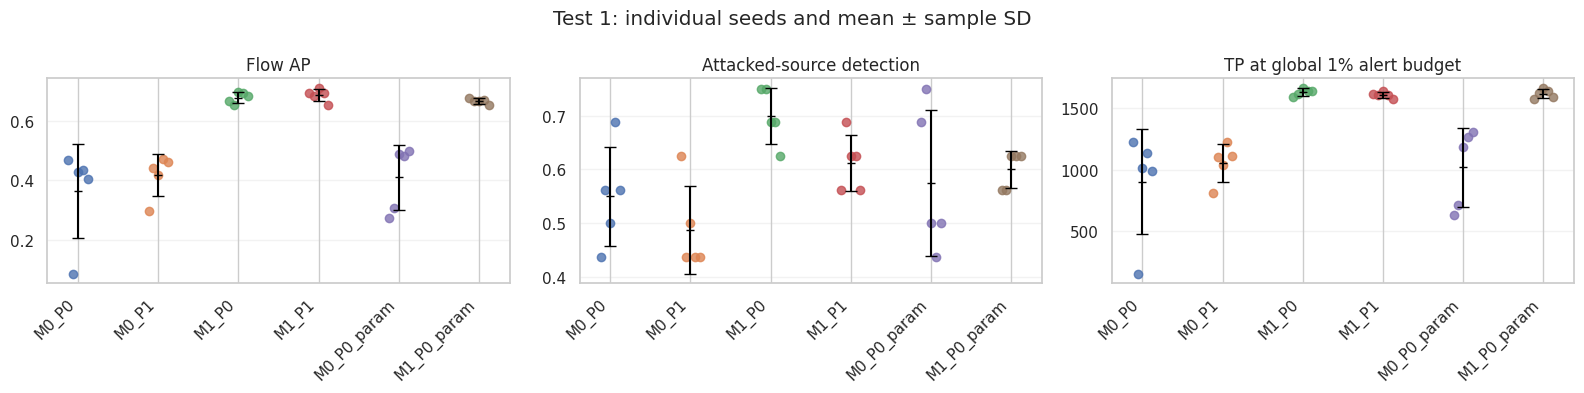

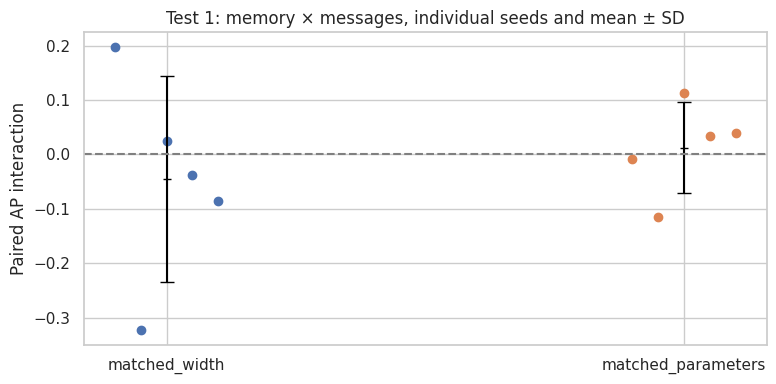

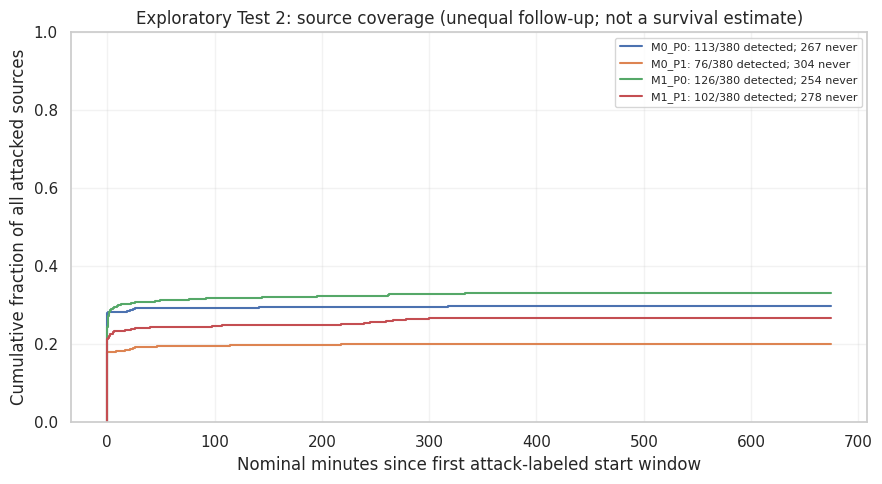

Saved results to: /content/drive/MyDrive/nids-mitre/results_stgnn_memory_message_factorial_v1
Completed training runs: 30 / 30


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, metric, title in zip(axes, ['AUC-PR', 'source_detection_fraction', 'TP_at_budget'],
                            ['Flow AP', 'Attacked-source detection', 'TP at global 1% alert budget']):
    for position, cell in enumerate(CELLS):
        group = test1[(test1.model == cell) & (test1.status == 'complete')]
        values = pd.to_numeric(group.get(metric, pd.Series(dtype=float)), errors='coerce')
        jitter = np.linspace(-0.12, 0.12, len(values))
        ax.scatter(position + jitter, values, alpha=0.8)
        if len(values):
            ax.errorbar(position, values.mean(), yerr=values.std() if len(values) > 1 else 0,
                        color='black', fmt='_', capsize=4)
    ax.set_xticks(range(len(CELLS)), CELLS, rotation=45, ha='right')
    ax.set_title(title)
    ax.grid(axis='y', alpha=0.25)
fig.suptitle('Test 1: individual seeds and mean ± sample SD')
fig.tight_layout()
fig.savefig(OUTPUT / 'test1_factorial_seeds.png', dpi=180, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
for position, cohort in enumerate(COHORTS):
    selected = paired_contrasts[(paired_contrasts.split == 'test1') &
                                (paired_contrasts.cohort == cohort) &
                                (paired_contrasts.metric == 'AUC-PR') &
                                (paired_contrasts.contrast == 'interaction')]
    values = selected.difference.dropna()
    ax.scatter(position + np.linspace(-0.1, 0.1, len(values)), values)
    if len(values):
        ax.errorbar(position, values.mean(), yerr=values.std() if len(values) > 1 else 0,
                    color='black', fmt='_', capsize=5)
ax.axhline(0, color='gray', linestyle='--')
ax.set_xticks(range(len(COHORTS)), COHORTS)
ax.set_ylabel('Paired AP interaction')
ax.set_title('Test 1: memory × messages, individual seeds and mean ± SD')
fig.tight_layout()
fig.savefig(OUTPUT / 'test1_ap_interaction.png', dpi=180)
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
for cell in COHORTS['matched_width']:
    if cell not in champion_seeds:
        continue
    folder, _, _ = run_paths(cell, champion_seeds[cell])
    sources = pd.read_csv(folder / 'test2_source_detection.csv')
    detected = sources.event_observed.astype(bool)
    delays = np.sort(sources.loc[detected, 'nominal_first_hit_minutes'].to_numpy())
    max_followup = float(sources.nominal_followup_minutes.max())
    x = np.r_[0, delays, max_followup]
    coverage = np.r_[0, np.arange(1, len(delays) + 1) / len(sources), len(delays) / len(sources)]
    ax.step(x, coverage, where='post',
            label=f'{cell}: {len(delays)}/{len(sources)} detected; {int((~detected).sum())} never')
ax.set_xlabel('Nominal minutes since first attack-labeled start window')
ax.set_ylabel('Cumulative fraction of all attacked sources')
ax.set_ylim(0, 1)
ax.set_title('Exploratory Test 2: source coverage (unequal follow-up; not a survival estimate)')
ax.legend(fontsize=8)
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT / 'test2_source_cumulative_coverage.png', dpi=180)
plt.show()

write_json(OUTPUT / 'output_inventory.json', dict(
    manifest_sha256=MANIFEST_SHA256,
    training_complete=int(training_status.status.eq('complete').sum()),
    training_expected=len(CELLS) * len(SEEDS),
    selected_champions=champion_seeds,
    artifacts={
        'manifest.json': 'Configuration, exact graph fingerprints, software and source provenance',
        'factorial_models.py': 'Exact additional model implementation',
        'config_*.json': 'Per-cell configuration and parameter counts',
        'alignment/*_flows.parquet': 'Flow alignment, endpoints, times and labels; split in filename',
        'alignment/*_graphs.csv': 'Window-to-file mapping, counts and full graph hashes',
        'CELL/seed_N/checkpoint.pth': 'Best validation-AP state dictionary',
        'CELL/seed_N/record.json': 'Completion/failure status, threshold, validation metrics and checkpoint hash',
        'CELL/seed_N/*_scores.npz': 'Scores joined by flow_index and alignment hash',
        'CELL/seed_N/history.csv': 'Epoch-level losses, validation AP and timing',
        'CELL/seed_N/*_source_detection.csv': 'Every attacked source including censored misses',
        'CELL/seed_N/*_source_windows.csv': 'Source-window alerts and attack presence',
        'CELL/seed_N/*_daily_workload.csv': 'Calendar-day flow alert counts',
        'validation_all_seeds.csv': 'Validation records including failed runs',
        'champions_by_validation.csv': 'Champion choices and selection cutoffs',
        'frozen_selection.json': 'Selection record saved before factorial test inference',
        'test1_all_seeds.csv': 'All requested training seeds, including failures',
        'test2_champions.csv': 'Validation-selected champions only',
        'factor_contrasts_by_seed.csv': 'Paired individual contrasts and explicit missing runs',
        'factor_contrasts.csv': 'Single factor-contrast summary for both capacity comparisons',
        'test1_seed_summary.csv': 'Means, SDs, ranges and completed-run denominators',
        'comparison_with_external_baselines.csv': 'External Edge GRU and optional historical ST Uniform',
        'test2_source_1195_sensitivity.csv': 'Exploratory subset metrics and prevalence',
    }))
print('Saved results to:', OUTPUT)
print('Completed training runs:', int(training_status.status.eq('complete').sum()), '/', len(training_status))
if not training_status.status.eq('complete').all():
    print('Incomplete experiment: review training_status.csv; failed seeds remain in the tables.')

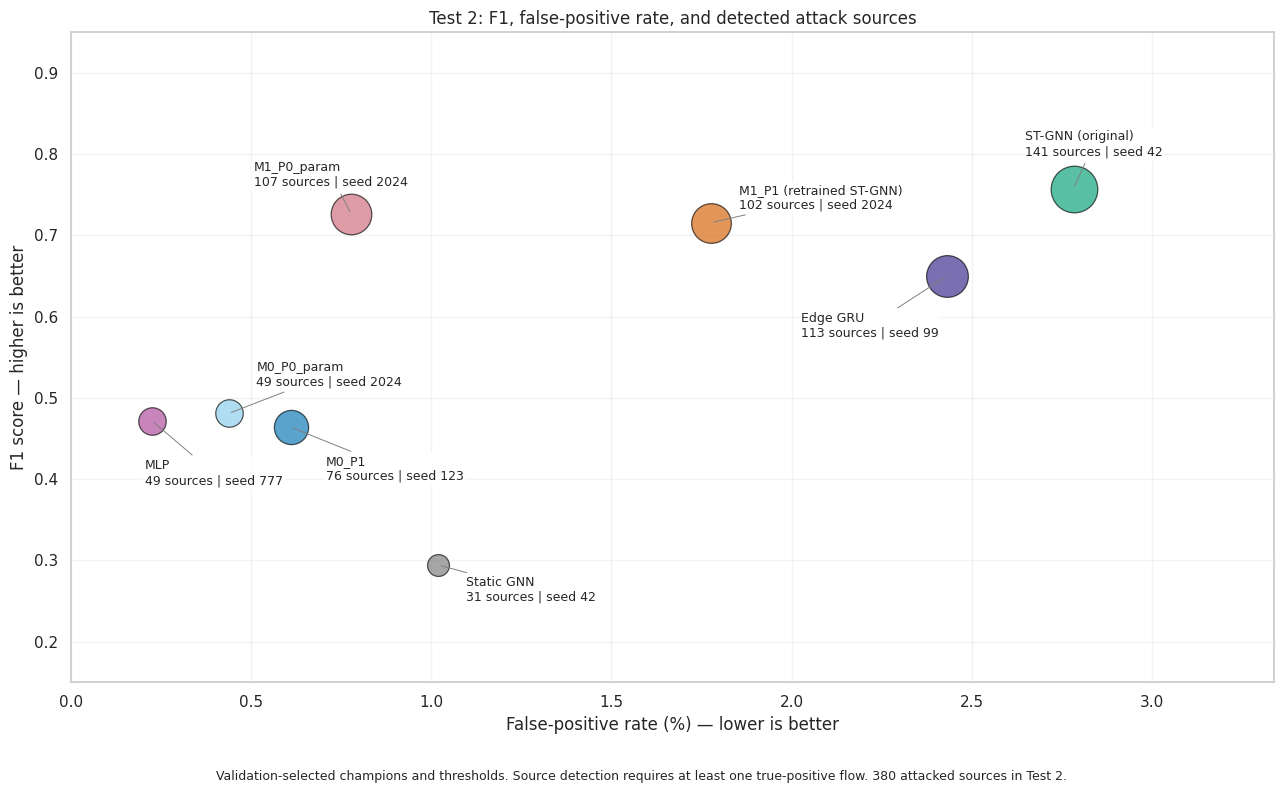

,model,seed,F1,FPR_percent,sources_detected
0,M0_P0_param,2024,0.4809,0.438,49
1,M0_P1,123,0.4639,0.610,76
2,M1_P0_param,2024,0.7265,0.778,107
3,M1_P1,2024,0.7157,1.776,102
4,MLP,777,0.4722,0.224,49
5,Static GNN,42,0.2944,1.019,31
6,ST-GNN (original),42,0.7576,2.783,141
7,Edge GRU,99,0.6502,2.431,113


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Existing Test 2 results.
ROOT = Path("/content/drive/MyDrive/nids-mitre")
FACTORIAL_DIR = ROOT / "results_stgnn_memory_message_factorial_v1"
HISTORICAL_DIR = ROOT / "results_comparison/temporal_operational_v1"

# Six factorial configurations.
factorial = pd.read_csv(FACTORIAL_DIR / "test2_champions.csv")
factorial = factorial.loc[factorial["status"].eq("complete")].copy()

columns = [
    "model", "seed", "F1", "FPR",
    "sources_detected", "attacked_sources",
]
factorial = factorial[columns]

# Historical validation-selected champions.
historical_names = {
    "Simple MLP": "MLP",
    "Static GNN": "Static GNN",
    "ST-GNN": "ST-GNN (original)",
    "Edge GRU": "Edge GRU",
}

metrics = pd.read_csv(HISTORICAL_DIR / "flow_metrics_baselines.csv")
sources = pd.read_csv(HISTORICAL_DIR / "source_temporal_summary.csv")

metrics = metrics.loc[
    metrics["model"].isin(historical_names),
    ["model", "seed", "F1", "FPR"],
]
sources = sources.loc[
    sources["subset"].eq("All attacked sources")
    & sources["model"].isin(historical_names),
    ["model", "sources_detected", "attacked_sources"],
]

historical = metrics.merge(sources, on="model", validate="one_to_one")
historical["model"] = historical["model"].replace(historical_names)

data = pd.concat([factorial, historical[columns]], ignore_index=True)

order = [
    #"M0_P0", "M0_P1", "M1_P0", "M1_P1",
    "M0_P0_param", "M0_P1", "M1_P0_param", "M1_P1",
    "MLP", "Static GNN", "ST-GNN (original)", "Edge GRU",
]

missing = set(order) - set(data["model"])
assert not missing, f"Missing models: {sorted(missing)}"
assert data["model"].is_unique
assert data[columns].notna().all().all()
assert data["attacked_sources"].eq(380).all()

data = data.set_index("model").loc[order].reset_index()
data["FPR_percent"] = 100 * data["FPR"]

colors = {
    #"M0_P0": "#56B4E9",
    "M0_P1": "#0072B2",
    #"M1_P0": "#E69F00",
    "M1_P1": "#D55E00",
    "M0_P0_param": "#88CCEE",
    "M1_P0_param": "#CC6677",
    "MLP": "#AA4499",
    "Static GNN": "#777777",
    "ST-GNN (original)": "#009E73",
    "Edge GRU": "#332288",
}

# Label offsets in points; adjust these if labels overlap after a new run.
offsets = {
    #"M0_P0": (20, 10),
    "M0_P1": (25, -30),
    #"M1_P0": (20, -28),
    "M1_P1": (20, 18),
    "M0_P0_param": (20, 28),
    "M1_P0_param": (-70, 28),
    "MLP": (-5, -38),
    "Static GNN": (20, -18),
    "ST-GNN (original)": (-35, 32),
    "Edge GRU": (-105, -36),
}

# Matplotlib's s argument controls marker AREA in points squared.
AREA_PER_SOURCE = 8.0

fig, ax = plt.subplots(figsize=(13, 8))

# Draw larger circles first so smaller circles remain visible.
for _, row in data.sort_values("sources_detected", ascending=False).iterrows():
    name = row["model"]
    x, y = row["FPR_percent"], row["F1"]

    ax.scatter(
        x, y,
        s=AREA_PER_SOURCE * row["sources_detected"],
        color=colors[name],
        edgecolor="black",
        linewidth=0.9,
        alpha=0.65,
        zorder=3,
    )

    label = "M1_P1 (retrained ST-GNN)" if name == "M1_P1" else name
    ax.annotate(
        f"{label}\n"
        f"{int(row['sources_detected'])} sources | seed {int(row['seed'])}",
        xy=(x, y),
        xytext=offsets[name],
        textcoords="offset points",
        fontsize=9,
        ha="left",
        va="center",
        arrowprops=dict(arrowstyle="-", color="0.5", linewidth=0.7),
        bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.85),
        zorder=4,
    )

# Bubble-size legend.
size_handles = [
    ax.scatter(
        [], [], s=AREA_PER_SOURCE * count,
        facecolor="lightgray", edgecolor="black", alpha=0.65,
        label=f"{count} sources",
    )
    for count in [50, 100, 150]
]
# ax.legend(
#     handles=size_handles,
#     title="Detected attack sources\n(circle area)",
#     loc="lower right",
#     labelspacing=1.8,
#     borderpad=1.3,
# )

ax.set(
    xlabel="False-positive rate (%) — lower is better",
    ylabel="F1 score — higher is better",
    title="Test 2: F1, false-positive rate, and detected attack sources",
    xlim=(0, max(3.3, data["FPR_percent"].max() * 1.2)),
    ylim=(0.15, 0.95),
)
ax.grid(alpha=0.22)
ax.set_axisbelow(True)

fig.text(
    0.5, 0.015,
    "Validation-selected champions and thresholds. "
    "Source detection requires at least one true-positive flow. "
    "380 attacked sources in Test 2.",
    ha="center", fontsize=9,
)
fig.tight_layout(rect=(0, 0.05, 1, 1))

fig.savefig(FACTORIAL_DIR / "test2_f1_fpr_sources_bubbles.png",
            dpi=220, bbox_inches="tight")
fig.savefig(FACTORIAL_DIR / "test2_f1_fpr_sources_bubbles.pdf",
            bbox_inches="tight")
plt.show()

display(
    data[["model", "seed", "F1", "FPR_percent", "sources_detected"]]
    .round({"F1": 4, "FPR_percent": 3})
)

## Interpretation after the Colab run

Read paired per-seed effects and their spread before interpreting the means. A positive
interaction means that the message effect is larger with persistent memory, on that metric's
scale. AP is nonlinear: an AP interaction is a descriptive factorial contrast, not a universal
causal effect or evidence of attack-stage recognition. Check source coverage and equal-budget
TP alongside pooled AP, and examine the source 1195 exclusion.

Compare both capacity settings. Width matching preserves the existing nodewise ablation;
parameter matching adds nodewise depth and controls total trainable capacity approximately.
Neither makes a GAT and an MLP identical learning problems. Graph normalization, current-window
summaries, retrospective features, and the original labels are shared limitations.

Test 2 has been explored in previous experiments. Freeze the chosen design and thresholds
before evaluating a new campaign/day for independent confirmation. This notebook does not
infer lateral movement or rebuild a causal availability time axis; those require later experiments.